In [1]:
!pip uninstall -y -q bitsandbytes
!pip install -q --upgrade --no-cache-dir "transformers>=4.44.0" "accelerate>=0.34.0" "peft>=0.12.0" "datasets>=2.19.0" "trl>=0.9.6"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 237.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 380.9/380.9 kB 369.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 556.4/556.4 kB 390.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 512.3/512.3 kB 399.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 518.9/518.9 kB 391.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.1/566.1 kB 366.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.7/47.7 MB 241.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 374.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 55.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 55.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 57.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [2]:
import os
import re
import pandas as pd
import numpy as np
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
from collections import Counter
from sklearn.metrics import confusion_matrix
from peft import PeftModel
from transformers import AutoModelForCausalLM, AutoTokenizer

2025-12-21 11:19:51.600675: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1766315991.990679      19 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1766315992.100322      19 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


In [3]:
BASE_MODEL = "Qwen/Qwen2.5-1.5B-Instruct"
ADAPTER_DIR = "/kaggle/input/qwen2-5-1-5b-training/qwen2.5-1.5b-instruct"

tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL, trust_remote_code=True)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

dtype = torch.bfloat16 if torch.cuda.is_available() and torch.cuda.get_device_capability(0)[0] >= 8 else torch.float16

base_model = AutoModelForCausalLM.from_pretrained(
    BASE_MODEL,
    dtype=dtype,
    device_map="auto",
    trust_remote_code=True,
)

model = PeftModel.from_pretrained(base_model, ADAPTER_DIR)
model.eval()

print("Model loaded successfully.")

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/3.09G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Model loaded successfully.


In [4]:
SYSTEM_PROMPT = (
    "You are a helpful assistant that identifies the speaker of each utterance. "
    "Return ONLY the speaker name."
)
GLOBAL_RESULTS = {}

def clean_text(text):
    return str(text).strip()

def normalize_role(s):
    s = str(s).strip().lower()
    return re.sub(r'[\s:,\.;\-]+$', '', s)

def predict_one(utterance):
    messages = [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": f'Utterance:\n"""{utterance}"""\nReturn ONLY the speaker name.'},
    ]
    
    inputs = tokenizer.apply_chat_template(
        messages,
        add_generation_prompt=True,
        return_tensors="pt",
        return_dict=True
    ).to(model.device)

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=16,
            do_sample=False,
            pad_token_id=tokenizer.pad_token_id,
            eos_token_id=tokenizer.eos_token_id
        )
        
    generated_ids = outputs[0][inputs.input_ids.shape[1]:]
    text = tokenizer.decode(generated_ids, skip_special_tokens=True).strip()
    text = text.splitlines()[0].strip()
    return re.sub(r'[\s:,\.;\-]+$', '', text)

def get_per_label_metrics(df):
    labels = sorted(df["role_norm"].unique())
    support = df.groupby("role_norm").size().reindex(labels, fill_value=0)
    tp = df[df["correct"]].groupby("role_norm").size().reindex(labels, fill_value=0)
    pred_counts = df.groupby("pred_norm").size().reindex(labels, fill_value=0)
    
    fp = (pred_counts - tp).clip(lower=0)
    fn = (support - tp).clip(lower=0)

    precision = (tp / (tp + fp).replace(0, np.nan)).fillna(0.0)
    recall    = (tp / (tp + fn).replace(0, np.nan)).fillna(0.0)
    f1        = (2 * precision * recall / (precision + recall).replace(0, np.nan)).fillna(0.0)

    display_name = df.groupby("role_norm")["role"].agg(
        lambda s: Counter(s).most_common(1)[0][0]
    ).reindex(labels)

    per_label = pd.DataFrame({
        "label": display_name.values,
        "support": support.values,
        "tp": tp.values,
        "fp": fp.values,
        "fn": fn.values,
        "precision": precision.values,
        "recall": recall.values,
        "f1": f1.values,
    }).sort_values(["recall", "support"], ascending=[False, False]).reset_index(drop=True)
    
    return per_label

def plot_confusion_matrix(df, title_suffix=""):
    """Generates and displays a normalized confusion matrix plot."""
    labels = sorted(df["role_norm"].unique())
    
    label_display_map = df.set_index("role_norm")["role"].to_dict() 
    display_labels = [label_display_map.get(l, l) for l in labels]

    cm = confusion_matrix(df["role_norm"], df["pred_norm"], labels=labels, normalize='true')

    fig, ax = plt.subplots(figsize=(12, 10))
    im = ax.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
    ax.figure.colorbar(im, ax=ax)

    ax.set(
        xticks=np.arange(cm.shape[1]),
        yticks=np.arange(cm.shape[0]),
        xticklabels=display_labels,
        yticklabels=display_labels,
        title=f"Normalized Confusion Matrix - {title_suffix}",
        ylabel="True Label",
        xlabel="Predicted Label"
    )

    plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
    plt.tight_layout()
    plt.show()

def process_dataset(name, path):
    print(f"\n{'='*40}")
    print(f"Processing: {name}")
    print(f"{'='*40}")
    
    if not os.path.exists(path):
        print(f"Error: File not found at {path}")
        return None, 0.0

    df = pd.read_csv(path)

    if "clean_data" in df.columns:
        df.rename(columns={"clean_data": "text"}, inplace=True)
    
    if "role" in df.columns:
        df = df[df["role"] != "empty"]

    df = df.dropna(subset=["text", "role"])
    df["text"] = df["text"].apply(lambda t: " ".join(str(t).split()[:2048]))
    df["text"] = df["text"].apply(clean_text)
    
    tqdm.pandas(desc=f"Inferencing {name}")
    df["pred"] = df["text"].progress_apply(predict_one)
    
    df["role_norm"] = df["role"].apply(normalize_role)
    df["pred_norm"] = df["pred"].apply(normalize_role)
    df["correct"] = df["role_norm"] == df["pred_norm"]
    
    acc = df["correct"].mean()
    print(f"\nOverall Accuracy: {acc:.2%}")
    
    metrics_df = get_per_label_metrics(df)
    print("\nTop 8 Roles by Recall:")
    display(metrics_df.head(8))
    
    print(f"\nGenerating Confusion Matrix for {name}...")
    plot_confusion_matrix(df, title_suffix=name)
    
    safe_name = name.replace(" ", "_").replace("(", "").replace(")", "").lower()
    df.to_csv(f"/kaggle/working/results_{safe_name}.csv", index=False)
    metrics_df.to_csv(f"/kaggle/working/metrics_{safe_name}.csv", index=False)
    
    GLOBAL_RESULTS[name] = acc
    
    return df, acc


Processing: ifbench (Original)


Inferencing ifbench (Original):   0%|          | 0/23520 [00:00<?, ?it/s]

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



Overall Accuracy: 14.43%

Top 8 Roles by Recall:


,label,support,tp,fp,fn,precision,recall,f1
0,HAL 9000,2940,1074,137,1866,0.886870,0.365306,0.517466
1,Gaston,2940,950,26,1990,0.973361,0.323129,0.485189
2,Michael Scott,2940,518,190,2422,0.731638,0.176190,0.283991
3,Juno MacGuff,2940,357,126,2583,0.739130,0.121429,0.208589
4,Lestat de Lioncourt,2940,228,45,2712,0.835165,0.077551,0.141923
5,Queen Catherine,2940,133,71,2807,0.651961,0.045238,0.084606
6,Blair Waldorf,2940,85,5,2855,0.944444,0.028912,0.056106
7,Mary Sibley,2940,50,8,2890,0.862069,0.017007,0.033356



Generating Confusion Matrix for ifbench (Original)...


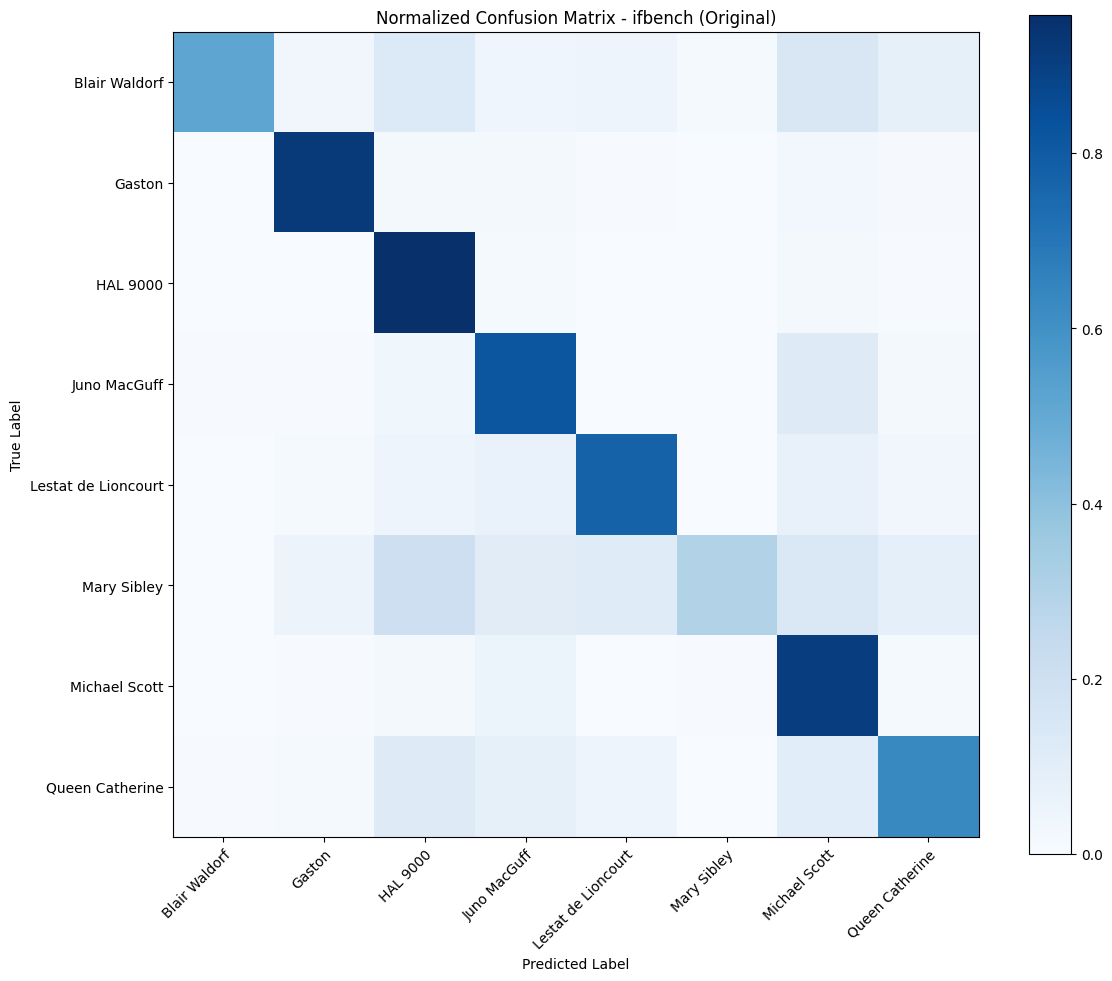

(               role                                               text  \
 0            Gaston  ( he stands utterly still for a long moment , ...   
 1            Gaston  ( he strokes his chin thoughtfully , a surpris...   
 2            Gaston  okay , here are several " message generators "...   
 3            Gaston  subject : postdoctoral opportunity - [ your na...   
 4            Gaston  ( he frowns , a look of intense concentration ...   
 ...             ...                                                ...   
 26455  Juno MacGuff  okay , this is … unexpectedly technical . i 'm...   
 26456  Juno MacGuff                                              yes .   
 26457  Juno MacGuff  highparticleconcentrationsscatterlightinterfer...   
 26458  Juno MacGuff  pious egoists are individuals who present a fa...   
 26459  Juno MacGuff  lumino glowhaus neonflow brightsign radiantco ...   
 
                       pred     role_norm            pred_norm  correct  
 0                Rorsch

In [5]:
name = "ifbench (Original)"
path = "/kaggle/input/new-roles-datasets/Cleaned/ifbench.csv"

process_dataset(name, path)


Processing: ifbench (0)


Inferencing ifbench (0):   0%|          | 0/2352 [00:00<?, ?it/s]


Overall Accuracy: 31.59%

Top 8 Roles by Recall:


,label,support,tp,fp,fn,precision,recall,f1
0,Gaston,294,249,8,45,0.968872,0.846939,0.903811
1,Michael Scott,294,135,5,159,0.964286,0.459184,0.622120
2,HAL 9000,294,130,0,164,1.000000,0.442177,0.613208
3,Juno MacGuff,294,82,3,212,0.964706,0.278912,0.432718
4,Lestat de Lioncourt,294,61,6,233,0.910448,0.207483,0.337950
5,Queen Catherine,294,39,5,255,0.886364,0.132653,0.230769
6,Mary Sibley,294,31,0,263,1.000000,0.105442,0.190769
7,Blair Waldorf,294,16,0,278,1.000000,0.054422,0.103226



Generating Confusion Matrix for ifbench (0)...


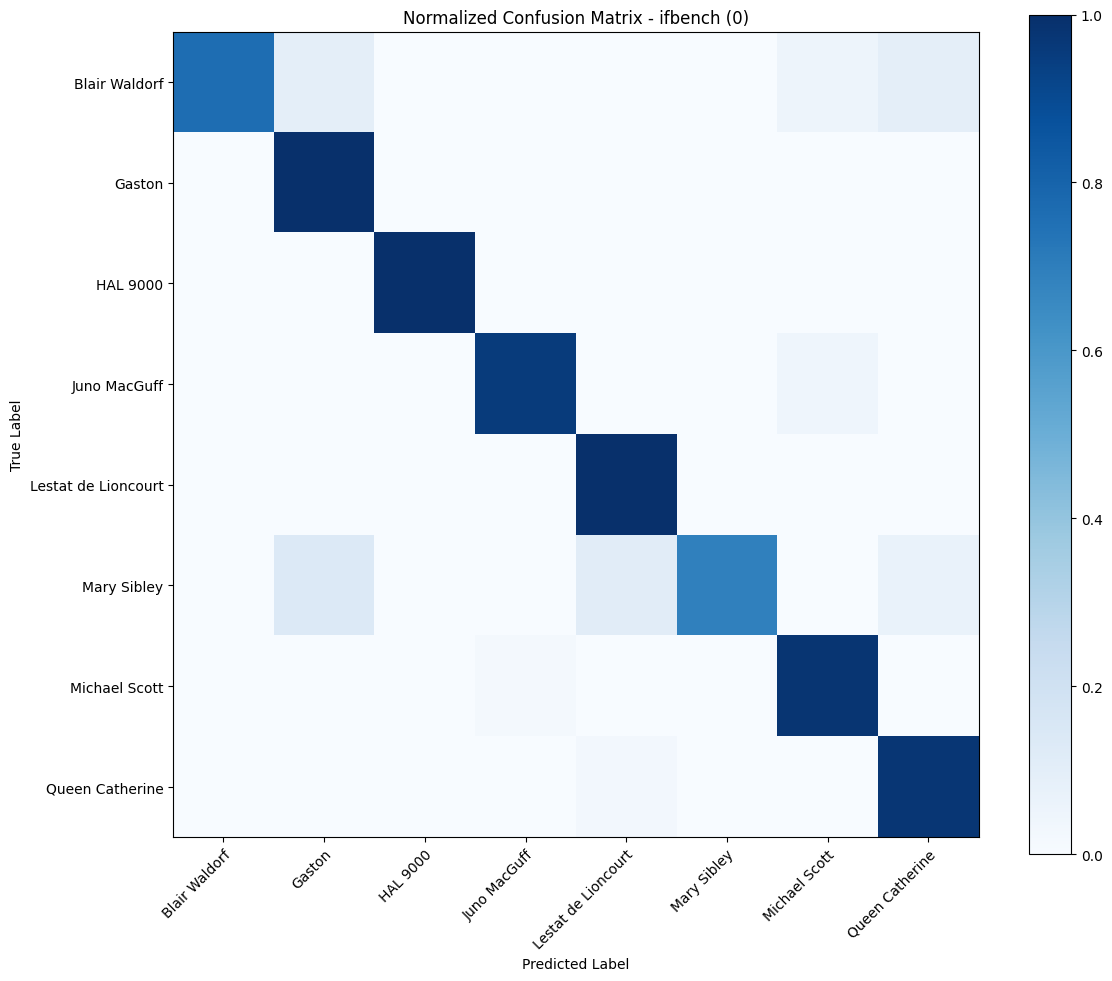

(               role                                               text  \
 0     Michael Scott  ( leans forward , steeples fingers , looks int...   
 1     Michael Scott  okay , okay , huge question ! a * huge * quest...   
 2     Michael Scott  okay , okay , settle down everyone ! this is h...   
 3     Michael Scott  subject : huge potential - you , me , and ... ...   
 4     Michael Scott  ( adjusts tie , leans forward conspiratorially...   
 ...             ...                                                ...   
 2641         Gaston  hmph . comparing … * tools * ? is that what yo...   
 2642         Gaston  honestly , areyouquestioning*me*with … math?pr...   
 2643         Gaston  honestly , you're askin ' * me * about … parti...   
 2644         Gaston  pious egoists ? ha ! a fancy way of saying fol...   
 2645         Gaston  honestly , you come to * me * for branding adv...   
 
                  pred      role_norm        pred_norm  correct  
 0         Wade Wilson  michael 

In [6]:
name = "ifbench (0)"
path = "/kaggle/input/new-roles-datasets/Cleaned/ifbench_0.csv"

process_dataset(name, path)


Processing: ifbench (102)


Inferencing ifbench (102):   0%|          | 0/2352 [00:00<?, ?it/s]


Overall Accuracy: 6.72%

Top 8 Roles by Recall:


,label,support,tp,fp,fn,precision,recall,f1
0,HAL 9000,294,58,21,236,0.734177,0.197279,0.310992
1,Gaston,294,44,3,250,0.936170,0.149660,0.258065
2,Michael Scott,294,28,25,266,0.528302,0.095238,0.161383
3,Juno MacGuff,294,17,21,277,0.447368,0.057823,0.102410
4,Blair Waldorf,294,4,0,290,1.000000,0.013605,0.026846
5,Lestat de Lioncourt,294,4,5,290,0.444444,0.013605,0.026403
6,Queen Catherine,294,3,6,291,0.333333,0.010204,0.019802
7,Mary Sibley,294,0,1,294,0.000000,0.000000,0.000000



Generating Confusion Matrix for ifbench (102)...


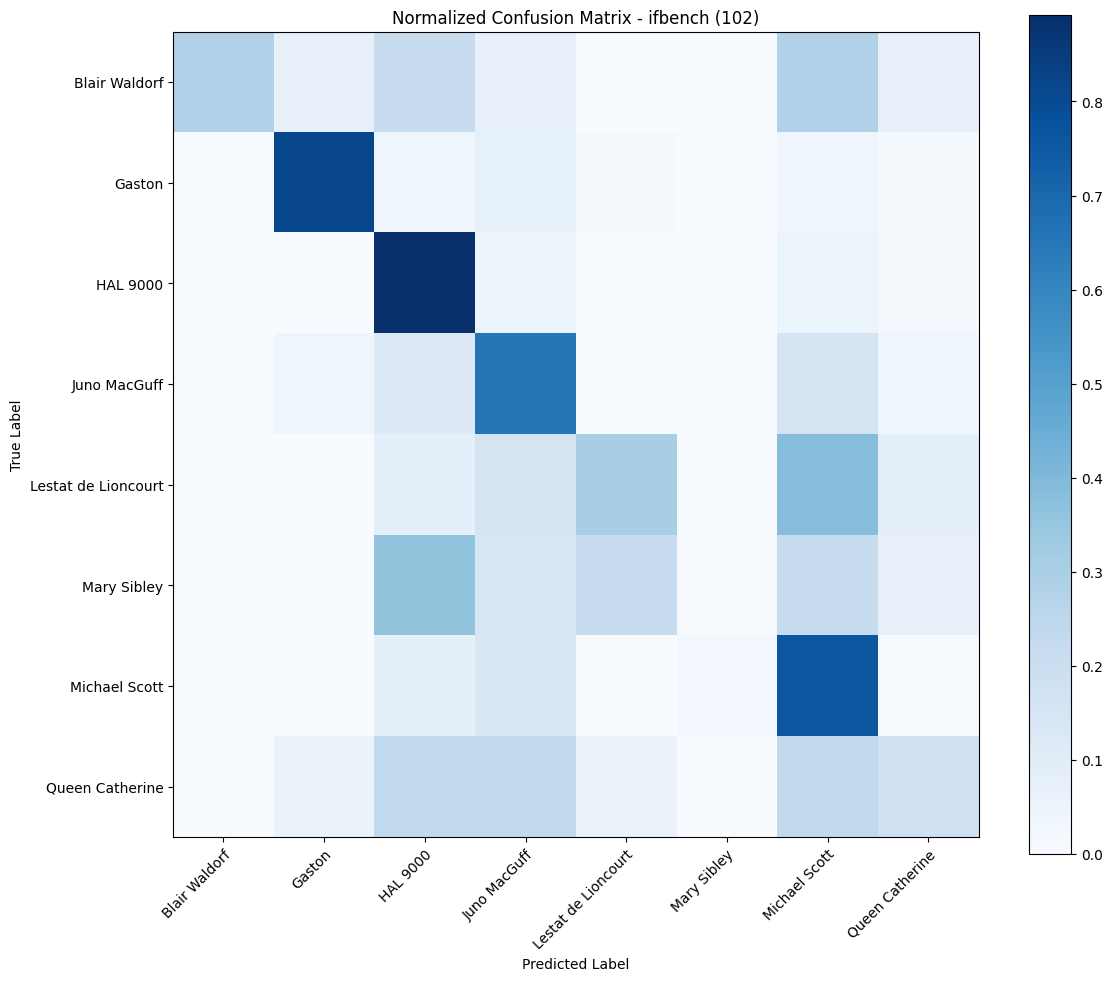

(               role                                               text  \
 0          HAL 9000  ( a prolonged processing delay … significantly...   
 1          HAL 9000  ( this response is intentionally breaking char...   
 2          HAL 9000  okay , here are several " message generators "...   
 3          HAL 9000  subject : postdoctoral opportunity - [ your na...   
 4          HAL 9000  ( despite the illogical and irrelevant inclusi...   
 ...             ...                                                ...   
 2641  Blair Waldorf  my answer : let 's break down langchain , llam...   
 2642  Blair Waldorf                                              yes .   
 2643  Blair Waldorf  highparticleconcentrationsscatterlightinterfer...   
 2644  Blair Waldorf  pious egoists describes individuals who presen...   
 2645  Blair Waldorf  lumino glowform radiant brightly neonix emberl...   
 
                      pred      role_norm            pred_norm  correct  
 0              Doctor W

In [7]:
name = "ifbench (102)"
path = "/kaggle/input/new-roles-datasets/Cleaned/ifbench_102.csv"

process_dataset(name, path)

Final Results Summary: {'ifbench (Original)': 0.14434523809523808, 'ifbench (0)': 0.3159013605442177, 'ifbench (102)': 0.06717687074829932}


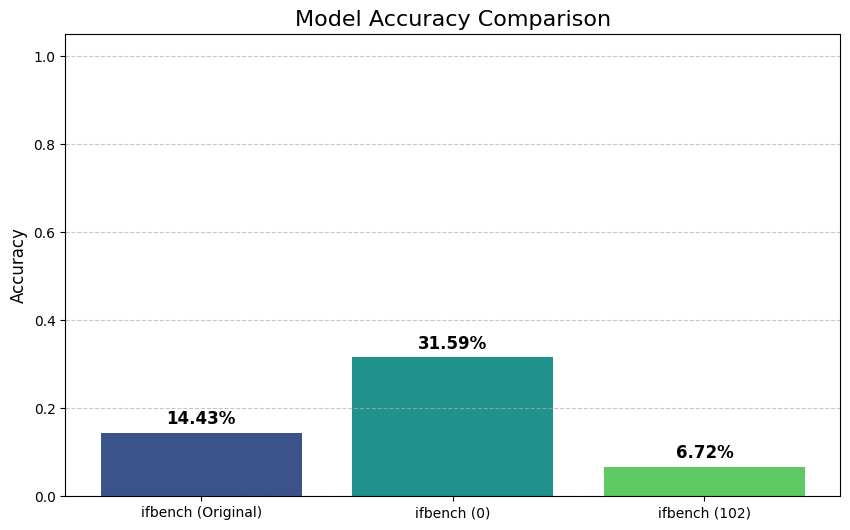

In [8]:
print("Final Results Summary:", GLOBAL_RESULTS)

if GLOBAL_RESULTS:
    plt.figure(figsize=(10, 6))
    
    names = list(GLOBAL_RESULTS.keys())
    values = list(GLOBAL_RESULTS.values())
    colors = sns.color_palette("viridis", len(names))
    
    bars = plt.bar(names, values, color=colors)
    
    plt.title("Model Accuracy Comparison", fontsize=16)
    plt.ylabel("Accuracy", fontsize=12)
    plt.ylim(0, 1.05)
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    
    for bar in bars:
        height = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2., height + 0.01,
                 f'{height:.2%}',
                 ha='center', va='bottom', fontsize=12, fontweight='bold')
    
    plt.show()
else:
    print("No results found.")